# 5 Brownian dynamics

## Brownian motion: inertia and diffusion

<div style="background-color:#f0f8ff; border:2px solid #4682b4; padding:12px; border-radius:4px;">
<strong>Note:</strong> This notebook contains the code for section 5.3 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

<a id="langevin"></a>
## 5.3 Brownian motion

Inertial regime, Langevin equation (Eq. (5.4)):

$$m\ddot x=-\gamma\dot x+\sqrt{2k_\mathrm{B}T\gamma}\,W(t),$$

Friction coefficient: $\gamma=6\pi\eta R$ 

Diffusion coefficient: $D=k_\mathrm{B}T/\gamma$. 

Momentum relaxation time: $\tau=m/\gamma$. 

Ballistic regime: $t\ll\tau$ (initial velocity is *retained*)

Diffusive regime: $t\gg\tau$ (initial velocity is *forgotten*)

Integrated stochastic force over $\Delta t$:  $\sqrt{2k_\mathrm{B}T\gamma\Delta t}\,w_i$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng() 

In [2]:
k_B = 1.380649e-23  # J/K
R = 1e-6            # m
eta = 0.001         # Pa * s
mass = 1.11e-14     # kg
T = 300.0           # K

gamma = 6 * np.pi * eta * R  # kg / s
tau = mass / gamma   # s
D = k_B * T / gamma  # m^2 / s
print(f"gamma = {gamma:.3e} kg/s")
print(f"tau = {tau:.3e} s")
print(f"D = {D:.3e} m²/s")

gamma = 1.885e-08 kg/s
tau = 5.889e-07 s
D = 2.197e-13 m²/s


<a id="inertial-finite-differences"></a>
Let's simulate the **inertial regime** with **finite differences**.

**Discretized Langevin equation:** see Eqs. (5.5) in the book.

**Numerical solution:** see Eqs. (5.6) in the book.

We can reorganize the terms in Eqs. (5.6) and have the following **equivalent** formulation:

$$v_i=\frac{1}{1 + \frac{\Delta t}{\tau}} \left( v_{i-1}+\sqrt{\frac{2k_\mathrm{B} T}{m}\, \frac{\Delta t}{\tau}} \, w_i \right),\qquad x_i=x_{i-1}+v_i\,\Delta t.$$

where we define: $v_i=\frac{x_i \,- \,x_{i-1}}{\Delta t}$
and $w_i\, \in \, \mathcal{N}(0, 1)$ 

In [3]:
# dt < tau : to capture inertial regime 
dt = tau / 40
n_steps = 5000 

noise = rng.standard_normal(n_steps)  # noise, this is the w_i

velocity = np.zeros(n_steps + 1)
position = np.zeros(n_steps + 1)
# thermal equilibrium
velocity[0] = rng.normal(
    scale=np.sqrt(k_B * T / mass)
)  

Note the syntax: `rng.normal(loc=0.0, scale=1.0, size=None)`

In [4]:
thermal_kick = np.sqrt(2 * k_B * T / mass * dt / tau)

friction_ratio =  dt / tau

for i in range(n_steps):
    velocity[i + 1] = (
        (velocity[i] + thermal_kick * noise[i]) 
        / (1 + friction_ratio)
    )
    position[i + 1] = (
        position[i] + velocity[i + 1] * dt
    )

<a id="overdamped-finite-differences"></a>
Let's simulate the **overdamped regime** with **finite differences**.

**Discretized Langevin equation:** see Eqs. (5.5) with $m=0$

**Numerical solution:** see Eqs. (5.7) in the book.

$x_i=x_{i-1}+\sqrt{2D\Delta t}\,w_i$. 


We use the *same* Gaussian sequence below for a controlled comparison; it does **not** make the two algorithms identical.

Let's compare the overdamped solution to the inertial one.

For this, we use the *same* Gaussian sequence for `noise`, the one generated above.

In [5]:
overdamped_position = np.zeros(n_steps + 1)

for i in range(n_steps):
    overdamped_position[i + 1] = (
        overdamped_position[i]
        + np.sqrt(2 * D * dt) * noise[i]
    )

Let's plot the generated trajectories.

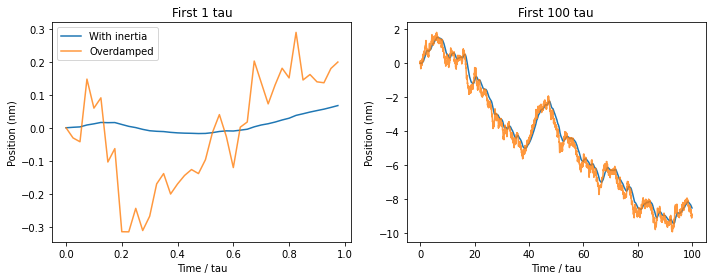

In [6]:
times = np.arange(n_steps + 1) * dt / tau

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, cutoff in zip(axes, [1, 100]):
    stop = np.searchsorted(times, cutoff)
    ax.plot(
        times[:stop], 
        position[:stop] * 1e9, 
        label="With inertia"
    )
    ax.plot(
        times[:stop], 
        overdamped_position[:stop] * 1e9,
        alpha=0.8, 
        label="Overdamped"
    )
    ax.set(
        xlabel="Time / tau", 
        ylabel="Position (nm)", 
        title=f"First {cutoff} tau"
    )
    
axes[0].legend()
plt.tight_layout();

Can you interpret the two plots?

If we use a time step $\Delta t = 10\tau$ for both inertial and overdamped trajectory generation?

<a id="msd"></a>
Let's analyse the **mean square displacement** for both inertial and overdamped trajectory.

We use the module.

In [7]:
# The same calculations, now available as a reusable module.
from pathlib import Path
import sys

sys.path.insert(0, '../05_modules/')
import brownian_dynamics as bd

We calculate MSD via ensemble average

In [8]:
n_ensemble = 1000
steps_ensemble = 1200
dt_ensemble = tau / 20

shared_noise = rng.standard_normal(
    (steps_ensemble, n_ensemble)
)

initial_velocities = rng.normal(
    scale=np.sqrt(k_B * T / mass), 
    size=n_ensemble
)

We generate the inertial and the overdamped (or viscous) ensemble

In [9]:
inertial_ensemble, velocities = bd.inertial_langevin(
    shared_noise, 
    dt_ensemble, 
    mass, 
    gamma, 
    T,
    velocity_initial=initial_velocities
)

viscous_ensemble = bd.overdamped_free(
    shared_noise, 
    dt_ensemble, 
    gamma, 
    T
)

We calculate the MSD for the two ensembles

In [10]:
lag_times = np.arange(steps_ensemble + 1) * dt_ensemble

msd_inertial = np.mean(inertial_ensemble**2, axis=1)

msd_viscous = np.mean(viscous_ensemble**2, axis=1)

# comparison with the theory (inertial case)
msd_theory_inertial = 2 * D * (
    lag_times - tau * (-np.expm1(-lag_times / tau))
)

# comparison with the theory (viscous case)
msd_theory_overdamped = 2 * D * lag_times

And we plot them

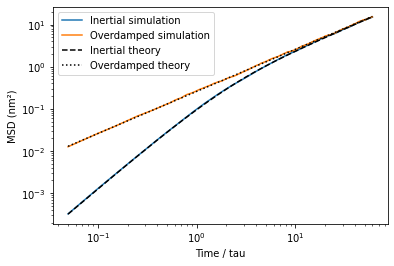

In [11]:
mask = lag_times > 0

plt.loglog(
    lag_times[mask] / tau, 
    msd_inertial[mask] * 1e18,
    label="Inertial simulation"
)

plt.loglog(
    lag_times[mask] / tau, 
    msd_viscous[mask] * 1e18,
    label="Overdamped simulation"
)

plt.loglog(
    lag_times[mask] / tau, 
    msd_theory_inertial[mask] * 1e18,
    "k--", 
    label="Inertial theory"
)

plt.loglog(
    lag_times[mask] / tau, 
    msd_theory_overdamped[mask] * 1e18,
    "k:", 
    label="Overdamped theory"
)

plt.xlabel("Time / tau")
plt.ylabel("MSD (nm²)")
plt.legend();

Following Exercise 5.3, we calculate the mean square displacement on a very long trajectory (time-MSD)

In [12]:
long_noise = rng.standard_normal(90000)
long_track = bd.overdamped_free(
    long_noise, 
    dt_ensemble, 
    gamma, 
    T
)

lags = np.unique(np.geomspace(1, 2500, 50).astype(int))

time_msd = np.empty(len(lags))

for j, lag in enumerate(lags):
    squared_displacements = (
        (long_track[lag:] - long_track[:-lag])**2
    )
    time_msd[j] = squared_displacements.mean()

Now we plot

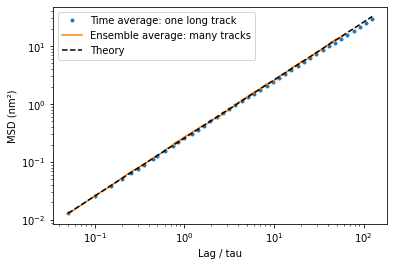

In [13]:
ensemble_msd = np.mean(viscous_ensemble**2, axis=1)

plt.loglog(
    lags * dt_ensemble / tau, 
    time_msd * 1e18,
    "o", 
    ms=3, 
    label="Time average: one long track"
)

plt.loglog(
    lag_times[1:] / tau, 
    ensemble_msd[1:] * 1e18,
    label="Ensemble average: many tracks"
)

plt.loglog(
    lags * dt_ensemble / tau, 
    2 * D * lags * dt_ensemble * 1e18,
    "k--", 
    label="Theory"
)

plt.xlabel("Lag / tau")
plt.ylabel("MSD (nm²)")
plt.legend();

<a id="questions"></a>
## Questions

Here you find the questions:

- [Q5: Inertial regime](#q5)
- [Q6: Overdamped regime](#q6)
- [Q7: Mean square displacement](#q7)
- [Q8: Module](#q8)

<a id="q5"></a>
**Question 5: Inertial regime.**  

Refer to [Langevin equation](#langevin) and [Inertial regime](#inertial-finite-differences).  

[Go back to questions](#questions)

a. What are the different terms appearing in the Langevin equation? Is there a reason why the friction coefficient $\gamma$ appears in both the friction and random-force terms?

b. In the notebook, the time step is chosen as `dt = tau / 40`. Could we get similar results if we use larger `dt` values? 

c. In the inertial regime how many initial conditions do we need for generating a trajectory? Is the initial position sufficient?

<a id="q6"></a>
**Question 6: Overdamped regime.** 

Refer to [Langevin equation](#langevin) and [Overdamped regime](#overdamped-finite-differences).  

[Go back to questions](#questions)

a. The notebook compares trajectories generated with and without inertia using the same random noise. Why do the trajectories differ at short times but show similar behavior at longer times?

b. Imagine you are experimentally observing the motion of a Brownian particle. Which of the two simulated trajectories, underdamped or overdamped, would you expect to observe?

c. Why is it computationally advantageous to use the overdamped approximation when studying Brownian motion over long times?

<a id="q7"></a>
**Question 7: Mean square displacement**  

Refer to [Mean square displacement](#msd).  

[Go back to questions](#questions)

a. Suppose we increase the particle mass while keeping the other parameters fixed. What would happen to the duration of the ballistic regime?

b. Suppose we increase the viscosity of the surrounding fluid. What would happen to the duration of the ballistic regime?

c. Observe the code:
```python
# comparison with the theory (inertial case)
msd_theory_inertial = 2 * D * (
    lag_times - tau * (-np.expm1(-lag_times / tau))
)
```
What is the function `np.expm1()`?


<a id="q8"></a>
**Question 8: Module.**  

Refer to [Mean square displacement](#msd) and the [module](../05_modules/brownian_dynamics.py)

[Go back to questions](#questions)

a. In the notebook, we generate a shared noise array that is passed to `inertial_langevin()` and `overdamped_free()` from the `brownian_dynamics.py` module. Suppose we instead generate two independent noise arrays, `noise_1` and `noise_2`, for the two functions. How would this affect the trajectories and MSD curves? 

b. In the `brownian_dynamics.py` module, `inertial_langevin()` updates the particle's position and velocity using a for loop, while `overdamped_free()` uses `np.cumsum()` to calculate positions directly. Why can the overdamped model use `np.cumsum()`, while the inertial model requires sequential updates?